# 4DGS-JEPA — Experiment 1 v3: Motion-Aware Path Supervision and Temporal Composition

This notebook is the third Colab-scale proof-of-concept implementation for **Experiment 1**.

It implements the four controlled variants:

1. **Endpoint**
2. **Endpoint + Path**
3. **Endpoint + Composition**
4. **Endpoint + Path + Composition**

### v3 revisions after analysing the 20-epoch rerun

The previous rerun established a strong reduction in direct--composed discrepancy, but the learned forecaster remained close to static persistence. The v3 run therefore changes the **causal predictive representation**, not merely the training duration:

- the Gaussian encoder now exposes explicit **causal velocity and acceleration** features computed only from the context history;
- historical coordinates are represented relative to the current state, making temporal change easier to identify across scenes with different absolute locations;
- current covariance and covariance change are represented in stable log-Cholesky coordinates;
- current geometry and causal motion use separate small MLP branches before hierarchical attention, preventing low-magnitude motion cues from being swamped by absolute geometry;
- fixed feature scaling puts position, velocity, acceleration, and covariance-change cues on comparable numerical ranges;
- the center geometry term now implements the paper's Huber penalty on the **Euclidean 3D center displacement**, rather than element-wise SmoothL1;
- the number of independently generated training trajectories is increased from 160 to **512**;
- training remains validation-selected with cosine LR decay and is capped at **15 epochs**, which already provides substantially more optimizer updates than the previous 20-epoch run because the training set is larger.

All methodological controls from v2 are retained: direct-only geometry supervision in Experiment 1, validation-only checkpoint selection, non-trivial composition metrics, separate seen-segment/unseen-segment partition tests, unseen-horizon direct and rollout FDE, and static/constant-velocity baselines.

### Leakage controls

Train, validation, and test trajectories use disjoint scene seeds. The student receives only the history ending at the context endpoint $t$. Velocity, acceleration, historical relative positions, and covariance changes are all computed strictly from that causal context history. Future states are used only as teacher/geometry targets, for validation checkpoint selection, or for final evaluation. The test set is never used for checkpoint selection. Unseen horizons and held-out partitions are never used for training. Constant velocity uses only the final two causal context states.


In [1]:
# Optional hardware summary (safe to run in Colab)
import os, platform
try:
    import psutil
    print("CPU cores:", psutil.cpu_count(logical=False))
    print("Logical CPUs:", psutil.cpu_count(logical=True))
    print("Memory (GB):", round(psutil.virtual_memory().total / 1e9, 2))
except Exception as exc:
    print("psutil summary unavailable:", exc)
print("Platform:", platform.platform())


CPU cores: 6
Logical CPUs: 12
Memory (GB): 89.63
Platform: Linux-6.6.122+-x86_64-with-glibc2.35


In [2]:
# ---------- Colab-friendly setup ----------
import os, math, json, random, time, shutil, copy
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass

def seed_all(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(0)


Device: cuda
GPU: NVIDIA A100-SXM4-40GB


In [3]:
@dataclass
class Config:
    # Synthetic benchmark
    num_groups: int = 3
    gaussians_per_group: int = 6
    seq_len: int = 24
    context_len: int = 4
    train_scenes: int = 512
    val_scenes: int = 32
    test_scenes: int = 48

    # Model
    token_dim: int = 48
    horizon_dim: int = 16
    transformer_heads: int = 4
    transformer_layers: int = 1
    transformer_dropout: float = 0.0

    # Optimization
    batch_size: int = 48
    eval_batch_size: int = 64
    epochs: int = 15
    lr: float = 1e-3
    min_lr: float = 1e-5
    weight_decay: float = 1e-5
    ema_tau: float = 0.99
    grad_clip: float = 1.0
    lambda_geo: float = 5.0
    lambda_path: float = 1.0
    lambda_comp: float = 0.5
    lambda_rep: float = 0.02
    lambda_cov_rep: float = 0.05
    var_floor: float = 0.5
    center_huber_delta: float = 0.10

    # Fixed scales for causal motion features (chosen from generator magnitudes,
    # not estimated from validation/test data).
    position_scale: float = 1.5
    relative_position_scale: float = 0.20
    velocity_scale: float = 0.05
    acceleration_scale: float = 0.01
    cov_delta_scale: float = 0.05

    # Evaluation / repetition
    seeds: Tuple[int, ...] = (0, 1, 2)
    train_horizons: Tuple[int, ...] = (1, 2, 4, 8)
    unseen_horizons: Tuple[int, ...] = (3, 6)

CFG = Config()
print(CFG)

BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
RESULT_DIR = BASE_DIR / '4dgs_jepa_exp1_results_v3'
# Avoid mixing a rerun with stale files from an earlier execution.
if RESULT_DIR.exists():
    shutil.rmtree(RESULT_DIR)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULT_DIR / 'config.json', 'w') as f:
    json.dump(asdict(CFG), f, indent=2)


Config(num_groups=3, gaussians_per_group=6, seq_len=24, context_len=4, train_scenes=512, val_scenes=32, test_scenes=48, token_dim=48, horizon_dim=16, transformer_heads=4, transformer_layers=1, transformer_dropout=0.0, batch_size=48, eval_batch_size=64, epochs=15, lr=0.001, min_lr=1e-05, weight_decay=1e-05, ema_tau=0.99, grad_clip=1.0, lambda_geo=5.0, lambda_path=1.0, lambda_comp=0.5, lambda_rep=0.02, lambda_cov_rep=0.05, var_floor=0.5, center_huber_delta=0.1, position_scale=1.5, relative_position_scale=0.2, velocity_scale=0.05, acceleration_scale=0.01, cov_delta_scale=0.05, seeds=(0, 1, 2), train_horizons=(1, 2, 4, 8), unseen_horizons=(3, 6))


In [4]:
# ---------- Geometry utilities ----------
def skew(v: torch.Tensor) -> torch.Tensor:
    x, y, z = v.unbind(-1)
    O = torch.zeros_like(x)
    return torch.stack([
        O, -z, y,
        z, O, -x,
        -y, x, O
    ], dim=-1).reshape(*v.shape[:-1], 3, 3)

def axis_angle_to_matrix(w: torch.Tensor) -> torch.Tensor:
    """Stable Rodrigues map, (..., 3) -> (..., 3, 3)."""
    W = skew(w)
    theta2 = (w * w).sum(dim=-1, keepdim=True)
    theta = torch.sqrt(theta2.clamp_min(1e-16))
    small = theta2 < 1e-6
    A = torch.where(
        small,
        1.0 - theta2 / 6.0 + theta2 * theta2 / 120.0,
        torch.sin(theta) / theta.clamp_min(1e-8),
    )
    B = torch.where(
        small,
        0.5 - theta2 / 24.0 + theta2 * theta2 / 720.0,
        (1.0 - torch.cos(theta)) / theta2.clamp_min(1e-8),
    )
    I = torch.eye(3, device=w.device, dtype=w.dtype).expand(*w.shape[:-1], 3, 3)
    return I + A[..., None] * W + B[..., None] * (W @ W)

def make_spd(log_scales: np.ndarray, rot: np.ndarray | None = None) -> np.ndarray:
    D = np.diag(np.exp(2.0 * log_scales).astype(np.float32))
    if rot is None:
        return D
    return (rot @ D @ rot.T).astype(np.float32)

def np_axis_angle_to_matrix(w: np.ndarray) -> np.ndarray:
    theta = float(np.linalg.norm(w))
    if theta < 1e-10:
        K = np.array([[0, -w[2], w[1]], [w[2], 0, -w[0]], [-w[1], w[0], 0]], dtype=np.float32)
        return np.eye(3, dtype=np.float32) + K
    a = w / theta
    K = np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]], dtype=np.float32)
    return (np.eye(3) + np.sin(theta) * K + (1 - np.cos(theta)) * (K @ K)).astype(np.float32)

def cov_to_log_cholesky(cov: torch.Tensor) -> torch.Tensor:
    """Stable 6-D SPD coordinate: log Cholesky diagonal + three off-diagonals."""
    I = torch.eye(3, dtype=cov.dtype, device=cov.device)
    L = torch.linalg.cholesky(cov + 1e-6 * I)
    diag = torch.diagonal(L, dim1=-2, dim2=-1).clamp_min(1e-8).log()
    off = torch.stack([L[..., 1, 0], L[..., 2, 0], L[..., 2, 1]], dim=-1)
    return torch.cat([diag, off], dim=-1)


In [5]:
# ---------- Controlled dynamic Gaussian worlds ----------
def generate_scene(seed: int, cfg: Config) -> Dict[str, np.ndarray]:
    rng = np.random.default_rng(seed)
    G, P, T = cfg.num_groups, cfg.gaussians_per_group, cfg.seq_len
    N = G * P
    group_ids = np.repeat(np.arange(G), P).astype(np.int64)

    # Compact canonical structures separated in 3D.
    group_centers = rng.uniform(-1.0, 1.0, size=(G, 3)).astype(np.float32)
    base_mu = np.zeros((N, 3), np.float32)
    base_cov = np.zeros((N, 3, 3), np.float32)
    local_phase = rng.uniform(0, 2 * np.pi, size=(N, 1)).astype(np.float32)
    local_dir = rng.normal(size=(N, 3)).astype(np.float32)
    local_dir /= np.linalg.norm(local_dir, axis=1, keepdims=True) + 1e-8
    local_amp = rng.uniform(0.0, 0.035, size=(N, 1)).astype(np.float32)
    local_freq = rng.uniform(0.10, 0.35, size=(N, 1)).astype(np.float32)
    scale_phase = rng.uniform(0, 2 * np.pi, size=(N, 3)).astype(np.float32)
    scale_amp = rng.uniform(0.0, 0.06, size=(N, 3)).astype(np.float32)

    for i in range(N):
        g = group_ids[i]
        base_mu[i] = group_centers[g] + rng.normal(0, 0.16, size=3)
        base_cov[i] = make_spd(rng.uniform(np.log(0.04), np.log(0.10), size=3))

    axes = rng.normal(size=(G, 3)).astype(np.float32)
    axes /= np.linalg.norm(axes, axis=1, keepdims=True) + 1e-8
    omega = rng.uniform(-0.045, 0.045, size=(G, 1)).astype(np.float32)
    ang_acc = rng.uniform(-0.002, 0.002, size=(G, 1)).astype(np.float32)
    velocity = rng.uniform(-0.035, 0.035, size=(G, 3)).astype(np.float32)
    accel = rng.uniform(-0.0015, 0.0015, size=(G, 3)).astype(np.float32)
    trans_amp = rng.uniform(0.0, 0.08, size=(G, 3)).astype(np.float32)
    trans_freq = rng.uniform(0.08, 0.18, size=(G, 1)).astype(np.float32)
    trans_phase = rng.uniform(0, 2 * np.pi, size=(G, 3)).astype(np.float32)

    # One group is static in about half the scenes.
    if seed % 2 == 0:
        omega[0] = 0
        ang_acc[0] = 0
        velocity[0] = 0
        accel[0] = 0
        trans_amp[0] = 0

    mu = np.zeros((T, N, 3), np.float32)
    cov = np.zeros((T, N, 3, 3), np.float32)
    group_R = np.zeros((T, G, 3, 3), np.float32)
    group_d = np.zeros((T, G, 3), np.float32)

    for t in range(T):
        tt = float(t)
        for g in range(G):
            angle = omega[g, 0] * tt + 0.5 * ang_acc[g, 0] * tt * tt
            Rg = np_axis_angle_to_matrix(axes[g] * angle)
            dg = (
                velocity[g] * tt
                + 0.5 * accel[g] * tt * tt
                + trans_amp[g] * np.sin(trans_freq[g, 0] * tt + trans_phase[g])
            )
            group_R[t, g] = Rg
            group_d[t, g] = dg
        for i in range(N):
            g = group_ids[i]
            r = local_amp[i] * np.sin(local_freq[i] * tt + local_phase[i]) * local_dir[i]
            log_s = scale_amp[i] * np.sin(0.12 * tt + scale_phase[i])
            U = np.diag(np.exp(log_s).astype(np.float32))
            Rg = group_R[t, g]
            mu[t, i] = Rg @ base_mu[i] + group_d[t, g] + r
            cov[t, i] = Rg @ U @ base_cov[i] @ U.T @ Rg.T

    return {
        'mu': mu,
        'cov': cov,
        'group_ids': group_ids,
        'group_R': group_R,
        'group_d': group_d,
    }

class GaussianWorldDataset(Dataset):
    def __init__(self, scene_seeds: List[int], cfg: Config):
        self.cfg = cfg
        self.scene_seeds = list(scene_seeds)
        self.scenes = [generate_scene(s, cfg) for s in self.scene_seeds]
        self.max_h = max(max(cfg.train_horizons), max(cfg.unseen_horizons))
        self.samples = []
        for si, _scene in enumerate(self.scenes):
            for t in range(cfg.context_len - 1, cfg.seq_len - self.max_h):
                self.samples.append((si, t))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        si, t = self.samples[idx]
        sc = self.scenes[si]
        return {
            'mu': torch.from_numpy(sc['mu']),
            'cov': torch.from_numpy(sc['cov']),
            'group_ids': torch.from_numpy(sc['group_ids']),
            't': torch.tensor(t, dtype=torch.long),
        }

def build_splits(cfg: Config):
    # Disjoint scene seeds: no trajectory continuation or scene reuse across splits.
    tr = list(range(10_000, 10_000 + cfg.train_scenes))
    va = list(range(20_000, 20_000 + cfg.val_scenes))
    te = list(range(30_000, 30_000 + cfg.test_scenes))
    return tr, va, te


In [6]:
# ---------- Motion-aware causal encoder + predictive model ----------
def _normalize_cov_coord(coord: torch.Tensor) -> torch.Tensor:
    """Fixed normalization for log-Cholesky coordinates.

    The first three entries are log diagonal Cholesky scales. The generator uses
    Gaussian standard deviations around 0.04--0.10, so centering around log(0.07)
    keeps current covariance features numerically comparable to other inputs.
    The remaining three Cholesky off-diagonal coordinates are scaled by 0.05.
    These constants are fixed a priori and never estimated from validation/test data.
    """
    diag = (coord[..., :3] - math.log(0.07)) / 0.5
    off = coord[..., 3:] / 0.05
    return torch.cat([diag, off], dim=-1)


def causal_gaussian_features(
    mu: torch.Tensor,
    cov: torch.Tensor,
    group_ids: torch.Tensor,
    cfg: Config,
):
    """Construct current-geometry and motion features from a causal history only.

    Args:
        mu:  [B,L,N,3], ending at the current context endpoint.
        cov: [B,L,N,3,3], ending at the same endpoint.
        group_ids: [B,N].

    No quantity at a time later than the final history element is accessed.
    """
    B, L, N, _ = mu.shape
    assert L == cfg.context_len and L >= 3

    cov_coord = cov_to_log_cholesky(cov)  # [B,L,N,6]
    cur_mu = mu[:, -1]
    cur_cov = cov_coord[:, -1]

    # Current geometry. Retain global position, but also expose group-relative
    # current geometry so local structure is less dependent on absolute scene translation.
    group_centers = []
    for g in range(cfg.num_groups):
        mask = (group_ids == g).float().unsqueeze(-1)
        group_centers.append((cur_mu * mask).sum(1) / mask.sum(1).clamp_min(1.0))
    group_centers = torch.stack(group_centers, dim=1)  # [B,G,3]
    bidx = torch.arange(B, device=mu.device)[:, None]
    cur_group_center = group_centers[bidx, group_ids]
    local_pos = cur_mu - cur_group_center

    onehot = F.one_hot(group_ids, num_classes=cfg.num_groups).float()
    exist = torch.ones(B, N, 1, device=mu.device, dtype=mu.dtype)
    geom = torch.cat([
        cur_mu / cfg.position_scale,
        local_pos / cfg.relative_position_scale,
        _normalize_cov_coord(cur_cov),
        exist,
        onehot,
    ], dim=-1)

    # Translation-relative position history: [mu_{t-L+1}-mu_t, ..., mu_{t-1}-mu_t].
    rel_hist = (mu[:, :-1] - cur_mu[:, None]) / cfg.relative_position_scale
    rel_hist = rel_hist.permute(0, 2, 1, 3).reshape(B, N, -1)

    # Explicit first- and second-order causal finite differences.
    velocity = (mu[:, -1] - mu[:, -2]) / cfg.velocity_scale
    prev_velocity = (mu[:, -2] - mu[:, -3]) / cfg.velocity_scale
    acceleration = (velocity - prev_velocity) * (cfg.velocity_scale / cfg.acceleration_scale)

    # Change in SPD covariance coordinates over the most recent context step.
    delta_cov = (cov_coord[:, -1] - cov_coord[:, -2]) / cfg.cov_delta_scale

    motion = torch.cat([rel_hist, velocity, acceleration, delta_cov], dim=-1)
    return geom, motion


class HierEncoder(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        # geom = current mu (3) + group-relative pos (3) + current SPD coord (6)
        #        + existence (1) + group one-hot (G)
        geom_dim = 3 + 3 + 6 + 1 + cfg.num_groups
        # motion = (L-1) relative positions + velocity + acceleration + covariance change
        motion_dim = 3 * (cfg.context_len - 1) + 3 + 3 + 6
        D = cfg.token_dim
        self.cfg = cfg
        self.geom_mlp = nn.Sequential(
            nn.Linear(geom_dim, D), nn.GELU(), nn.Linear(D, D)
        )
        self.motion_mlp = nn.Sequential(
            nn.Linear(motion_dim, D), nn.GELU(), nn.Linear(D, D)
        )
        self.fuse = nn.Sequential(nn.LayerNorm(D), nn.Linear(D, D), nn.GELU())
        enc_layer = nn.TransformerEncoderLayer(
            D,
            cfg.transformer_heads,
            dim_feedforward=2 * D,
            batch_first=True,
            norm_first=True,
            dropout=cfg.transformer_dropout,
        )
        self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
        self.type_embed = nn.Parameter(torch.randn(3, D) * 0.02)
        self.norm = nn.LayerNorm(D)

    def forward(self, mu_hist, cov_hist, group_ids):
        B, L, N, _ = mu_hist.shape
        geom, motion = causal_gaussian_features(mu_hist, cov_hist, group_ids, self.cfg)
        # Separate branches guarantee that the low-magnitude temporal signal has
        # a direct route into the primitive embedding rather than needing to be
        # discovered by subtracting absolute coordinates internally.
        gtok = self.fuse(self.geom_mlp(geom) + self.motion_mlp(motion))
        groups = []
        for g in range(self.cfg.num_groups):
            mask = (group_ids == g).float().unsqueeze(-1)
            groups.append((gtok * mask).sum(1) / mask.sum(1).clamp_min(1.0))
        otok = torch.stack(groups, dim=1)
        stok = otok.mean(dim=1, keepdim=True)
        tokens = torch.cat(
            [stok + self.type_embed[0], otok + self.type_embed[1], gtok + self.type_embed[2]],
            dim=1,
        )
        return self.norm(self.contextualizer(tokens))


class HorizonEmbedding(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(4, out_dim), nn.GELU(), nn.Linear(out_dim, out_dim))

    def forward(self, h):
        h = h.float().view(-1, 1)
        x = torch.cat([h / 8.0, torch.sin(h), torch.cos(h), torch.log1p(h)], dim=-1)
        return self.mlp(x)


class Transition(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        D = cfg.token_dim
        self.h = HorizonEmbedding(D)
        layer = nn.TransformerEncoderLayer(
            D,
            cfg.transformer_heads,
            dim_feedforward=2 * D,
            batch_first=True,
            norm_first=True,
            dropout=cfg.transformer_dropout,
        )
        self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)
        self.out = nn.Sequential(nn.LayerNorm(D), nn.Linear(D, D))

    def forward(self, z, h):
        he = self.h(h)[:, None, :]
        dz = self.out(self.net(z + he))
        return z + dz


class GeometryDecoder(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        D, H = cfg.token_dim, cfg.horizon_dim
        self.cfg = cfg
        self.h = HorizonEmbedding(H)
        self.group_head = nn.Sequential(nn.Linear(2 * D + H, 2 * D), nn.GELU(), nn.Linear(2 * D, 6))
        self.gauss_head = nn.Sequential(nn.Linear(2 * D + H, 2 * D), nn.GELU(), nn.Linear(2 * D, 6))

    def forward(self, z0, z1, source_mu, source_cov, group_ids, h):
        B, N, _ = source_mu.shape
        G = self.cfg.num_groups
        he = self.h(h)

        group0 = z0[:, 1:1 + G]
        group1 = z1[:, 1:1 + G]
        go = self.group_head(torch.cat([group0, group1, he[:, None].expand(B, G, -1)], dim=-1))

        # Bounds scale with elapsed time; they are comfortably above the generated
        # motion range and therefore do not impose a long-horizon static bottleneck.
        hscale = h.float().view(B, 1, 1)
        aa = (0.10 * hscale) * torch.tanh(go[..., :3])
        d = (0.10 * hscale) * torch.tanh(go[..., 3:])
        R = axis_angle_to_matrix(aa)

        g0 = z0[:, 1 + G:1 + G + N]
        g1 = z1[:, 1 + G:1 + G + N]
        po = self.gauss_head(torch.cat([g0, g1, he[:, None].expand(B, N, -1)], dim=-1))
        r = (0.025 * hscale) * torch.tanh(po[..., :3])
        log_s = (0.04 * hscale) * torch.tanh(po[..., 3:])

        bidx = torch.arange(B, device=source_mu.device)[:, None]
        R_i = R[bidx, group_ids]
        d_i = d[bidx, group_ids]
        pred_mu = (R_i @ source_mu.unsqueeze(-1)).squeeze(-1) + d_i + r
        U = torch.diag_embed(torch.exp(log_s))
        pred_cov = R_i @ U @ source_cov @ U.transpose(-1, -2) @ R_i.transpose(-1, -2)
        return {'mu': pred_mu, 'cov': pred_cov, 'R': R, 'd': d, 'r': r, 'log_s': log_s}


class JEPA(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.encoder = HierEncoder(cfg)
        self.transition = Transition(cfg)
        self.decoder = GeometryDecoder(cfg)


In [7]:
# ---------- Losses, temporal partitions, and rollout helpers ----------
def hier_distance(a, b, cfg: Config):
    G = cfg.num_groups
    s = 1 - F.cosine_similarity(a[:, 0], b[:, 0], dim=-1).mean()
    o = (1 - F.cosine_similarity(a[:, 1:1 + G], b[:, 1:1 + G], dim=-1)).mean()
    g = F.smooth_l1_loss(a[:, 1 + G:], b[:, 1 + G:])
    return s + o + g

def hier_distance_per_sample(a, b, cfg: Config):
    G = cfg.num_groups
    s = 1 - F.cosine_similarity(a[:, 0], b[:, 0], dim=-1)
    o = (1 - F.cosine_similarity(a[:, 1:1 + G], b[:, 1:1 + G], dim=-1)).mean(dim=-1)
    g = F.smooth_l1_loss(a[:, 1 + G:], b[:, 1 + G:], reduction='none').mean(dim=(-1, -2))
    return s + o + g

def huber_on_euclidean_displacement(pred_mu, tgt_mu, delta: float):
    # Paper definition: rho_delta(||mu_hat - mu_target||_2), averaged over B and N.
    dist = torch.linalg.norm(pred_mu - tgt_mu, dim=-1)
    d = torch.as_tensor(delta, dtype=dist.dtype, device=dist.device)
    penalty = torch.where(
        dist <= d,
        0.5 * dist.pow(2),
        d * (dist - 0.5 * d),
    )
    return penalty.mean()

def geometry_loss(pred_mu, pred_cov, tgt_mu, tgt_cov, cfg: Config):
    lmu = huber_on_euclidean_displacement(pred_mu, tgt_mu, cfg.center_huber_delta)
    pcoord = cov_to_log_cholesky(pred_cov)
    tcoord = cov_to_log_cholesky(tgt_cov)
    lcov = F.smooth_l1_loss(pcoord, tcoord)
    return lmu + 0.25 * lcov

def _vicreg_level(x: torch.Tensor, cfg: Config):
    x = x.reshape(-1, x.shape[-1])
    std = torch.sqrt(x.var(dim=0, unbiased=False) + 1e-4)
    lvar = F.relu(cfg.var_floor - std).pow(2).mean()
    xc = x - x.mean(0, keepdim=True)
    cov = (xc.T @ xc) / max(1, x.shape[0] - 1)
    off = cov - torch.diag(torch.diagonal(cov))
    lcov = off.pow(2).sum() / x.shape[1]
    return lvar + cfg.lambda_cov_rep * lcov

def rep_regularizer(z, cfg: Config):
    # Apply the variance/covariance regularizer separately at scene, group,
    # and Gaussian levels, matching the hierarchy described in the paper.
    G = cfg.num_groups
    return (
        _vicreg_level(z[:, :1], cfg)
        + _vicreg_level(z[:, 1:1 + G], cfg)
        + _vicreg_level(z[:, 1 + G:], cfg)
    ) / 3.0

# Training partitions contain only supervised segment lengths {1,2,4,8}.
TRAIN_PARTITIONS = {
    1: [[1]],
    2: [[1, 1]],
    4: [[2, 2], [1, 1, 2]],
    8: [[4, 4], [2, 2, 4]],
}

# Fixed primary rollout used for validation and the main target-accuracy table.
PRIMARY_PARTITIONS = {
    1: [1],
    2: [1, 1],
    3: [1, 2],       # unseen endpoint; seen segment lengths
    4: [2, 2],
    6: [2, 4],       # unseen endpoint; seen segment lengths
    8: [4, 4],
}

# Held-out decompositions whose *segment lengths were all seen in training*.
HELDOUT_SEEN_SEGMENT_PARTITIONS = {
    4: [[2, 1, 1], [1, 2, 1]],
    8: [[4, 2, 2], [2, 4, 2], [2, 2, 2, 2]],
}

# Harder tests that contain segment lengths not used as transition horizons in training.
UNSEEN_SEGMENT_PARTITIONS = {
    4: [[1, 3], [3, 1]],
    8: [[3, 5], [5, 3]],
}

def get_hist(batch, h_end, cfg: Config):
    # h_end is an absolute frame-index tensor [B]. Only the requested history is returned.
    mus, covs = [], []
    for b, tend in enumerate(h_end.tolist()):
        start = tend - cfg.context_len + 1
        assert start >= 0
        mus.append(batch['mu'][b, start:tend + 1])
        covs.append(batch['cov'][b, start:tend + 1])
    return torch.stack(mus), torch.stack(covs)

def ema_update(teacher, student, tau):
    with torch.no_grad():
        for pt, ps in zip(teacher.parameters(), student.parameters()):
            pt.data.mul_(tau).add_(ps.data, alpha=1 - tau)

def rollout_partition(model, z0, source_mu, source_cov, group_ids, parts):
    z, mu, cov = z0, source_mu, source_cov
    elapsed = 0
    zs, geoms = [], []
    for dlt in parts:
        h = torch.full((z.shape[0],), float(dlt), device=z.device)
        zn = model.transition(z, h)
        geom = model.decoder(z, zn, mu, cov, group_ids, h)
        elapsed += dlt
        z, mu, cov = zn, geom['mu'], geom['cov']
        zs.append((elapsed, z))
        geoms.append((elapsed, geom))
    return zs, geoms


In [8]:
# ---------- Validation: target accuracy only (never composition error) ----------
@torch.no_grad()
def evaluate_target_accuracy(model, ds, cfg: Config):
    """Validation criterion used for checkpoint selection.

    Uses only target-relative direct and rollout FDE on the *training horizons*.
    Composition error is deliberately excluded so composition-trained variants do
    not receive a model-selection advantage on the metric they explicitly optimize.
    """
    model.eval()
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    direct_vals, rollout_vals = [], []
    for batch in loader:
        batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        B = batch['mu'].shape[0]
        t = batch['t']
        gids = batch['group_ids']
        bidx = torch.arange(B, device=DEVICE)
        ctx_mu, ctx_cov = get_hist(batch, t, cfg)
        z0 = model.encoder(ctx_mu, ctx_cov, gids)
        src_mu = batch['mu'][bidx, t]
        src_cov = batch['cov'][bidx, t]

        for H in cfg.train_horizons:
            h = torch.full((B,), float(H), device=DEVICE)
            zd = model.transition(z0, h)
            gd = model.decoder(z0, zd, src_mu, src_cov, gids, h)
            gt_mu = batch['mu'][bidx, t + H]
            direct_vals.append(torch.linalg.norm(gd['mu'] - gt_mu, dim=-1).mean(dim=-1).cpu())

            parts = PRIMARY_PARTITIONS[H]
            _zs, geoms = rollout_partition(model, z0, src_mu, src_cov, gids, parts)
            gr = geoms[-1][1]
            rollout_vals.append(torch.linalg.norm(gr['mu'] - gt_mu, dim=-1).mean(dim=-1).cpu())

    direct = torch.cat(direct_vals).mean().item()
    rollout = torch.cat(rollout_vals).mean().item()
    score = 0.5 * (direct + rollout)
    return {'val_score': score, 'val_direct_fde': direct, 'val_rollout_fde': rollout}


In [9]:
# ---------- Training ----------
def train_variant(variant: str, seed: int, cfg: Config, train_ds, val_ds):
    seed_all(seed)
    model = JEPA(cfg).to(DEVICE)
    teacher = HierEncoder(cfg).to(DEVICE)
    teacher.load_state_dict(model.encoder.state_dict())
    for p in teacher.parameters():
        p.requires_grad_(False)
    teacher.eval()

    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs, eta_min=cfg.min_lr)
    train_loader = DataLoader(
        train_ds,
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=True,
    )

    history = []
    use_path = 'Path' in variant
    use_comp = 'Composition' in variant
    partition_rng = random.Random(100_000 + seed)

    best_val = float('inf')
    best_epoch = -1
    best_model_state = None
    best_teacher_state = None
    global_step = 0

    for epoch in range(cfg.epochs):
        model.train()
        teacher.eval()
        sums = {'total': 0.0, 'end': 0.0, 'geo': 0.0, 'path': 0.0, 'comp': 0.0, 'rep': 0.0}
        nstep = 0

        for step, batch in enumerate(train_loader):
            batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
            B = batch['mu'].shape[0]
            t = batch['t']
            gids = batch['group_ids']
            bidx = torch.arange(B, device=DEVICE)

            ctx_mu, ctx_cov = get_hist(batch, t, cfg)
            z0 = model.encoder(ctx_mu, ctx_cov, gids)

            # Cycle uniformly through training horizons; every variant sees the same schedule.
            Delta = cfg.train_horizons[global_step % len(cfg.train_horizons)]
            global_step += 1
            hD = torch.full((B,), float(Delta), device=DEVICE)
            tgt_end = t + Delta

            tgt_mu_hist, tgt_cov_hist = get_hist(batch, tgt_end, cfg)
            with torch.no_grad():
                zt = teacher(tgt_mu_hist, tgt_cov_hist, gids)

            zd = model.transition(z0, hD)
            l_end = hier_distance(zd, zt, cfg)

            src_mu = batch['mu'][bidx, t]
            src_cov = batch['cov'][bidx, t]
            gt_mu = batch['mu'][bidx, tgt_end]
            gt_cov = batch['cov'][bidx, tgt_end]
            gd = model.decoder(z0, zd, src_mu, src_cov, gids, hD)

            # IMPORTANT EXPERIMENT-1 DESIGN:
            # Every variant receives *direct* target-anchored geometry supervision only.
            # No composed geometry is matched to the future target here. Therefore the
            # Endpoint baseline does not receive hidden recurrent target supervision.
            l_geo = geometry_loss(gd['mu'], gd['cov'], gt_mu, gt_cov, cfg)

            # Same anti-collapse regularization for all variants: context + direct state.
            l_rep = 0.5 * (rep_regularizer(z0, cfg) + rep_regularizer(zd, cfg))
            l_path = torch.zeros((), device=DEVICE)
            l_comp = torch.zeros((), device=DEVICE)

            if use_path or use_comp:
                parts = partition_rng.choice(TRAIN_PARTITIONS[Delta])
                zs, _geoms = rollout_partition(model, z0, src_mu, src_cov, gids, parts)

                if use_path:
                    path_terms = []
                    for elapsed, zj in zs:
                        te = t + elapsed
                        mh, ch = get_hist(batch, te, cfg)
                        with torch.no_grad():
                            ztj = teacher(mh, ch, gids)
                        path_terms.append(hier_distance(zj, ztj, cfg))
                    l_path = torch.stack(path_terms).mean()

                if use_comp:
                    comp_terms = []
                    for elapsed, zj in zs:
                        hj = torch.full((B,), float(elapsed), device=DEVICE)
                        zdir = model.transition(z0, hj)
                        # Bidirectional stop-gradient formulation from the Method.
                        dc = hier_distance(zdir, zj.detach(), cfg)
                        cd = hier_distance(zj, zdir.detach(), cfg)
                        comp_terms.append(0.5 * (dc + cd))
                    l_comp = torch.stack(comp_terms).mean()

            total = (
                l_end
                + cfg.lambda_geo * l_geo
                + cfg.lambda_path * l_path
                + cfg.lambda_comp * l_comp
                + cfg.lambda_rep * l_rep
            )

            opt.zero_grad(set_to_none=True)
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            opt.step()
            ema_update(teacher, model.encoder, cfg.ema_tau)

            sums['total'] += float(total.detach())
            sums['end'] += float(l_end.detach())
            sums['geo'] += float(l_geo.detach())
            sums['path'] += float(l_path.detach())
            sums['comp'] += float(l_comp.detach())
            sums['rep'] += float(l_rep.detach())
            nstep += 1

        # Validate before changing the LR for the next epoch.
        val = evaluate_target_accuracy(model, val_ds, cfg)
        current_lr = opt.param_groups[0]['lr']
        row = {
            'epoch': epoch + 1,
            'lr': current_lr,
            **{f'train_{k}': v / max(1, nstep) for k, v in sums.items()},
            **val,
        }
        history.append(row)

        if val['val_score'] < best_val:
            best_val = val['val_score']
            best_epoch = epoch + 1
            best_model_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_teacher_state = {k: v.detach().cpu().clone() for k, v in teacher.state_dict().items()}

        print(
            f'[{variant} seed={seed}] epoch {epoch + 1:02d}/{cfg.epochs} '
            f'train={row["train_total"]:.4f} val={val["val_score"]:.4f} '
            f'(direct={val["val_direct_fde"]:.4f}, rollout={val["val_rollout_fde"]:.4f}) '
            f'lr={current_lr:.2e} best_epoch={best_epoch}'
        )
        scheduler.step()

    assert best_model_state is not None
    model.load_state_dict(best_model_state)
    teacher.load_state_dict(best_teacher_state)
    model.to(DEVICE).eval()
    teacher.to(DEVICE).eval()

    hist = pd.DataFrame(history)
    best_info = {
        'best_epoch': best_epoch,
        'best_val_score': best_val,
        'best_val_direct_fde': float(hist.loc[hist.epoch == best_epoch, 'val_direct_fde'].iloc[0]),
        'best_val_rollout_fde': float(hist.loc[hist.epoch == best_epoch, 'val_rollout_fde'].iloc[0]),
    }
    return model, teacher, hist, best_info


In [10]:
# ---------- Evaluation of learned variants ----------
@torch.no_grad()
def evaluate_model(model, ds, cfg: Config):
    model.eval()
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    primary_rows = []
    partition_rows = []
    horizons = tuple(sorted(set(cfg.train_horizons) | set(cfg.unseen_horizons)))

    for batch in loader:
        batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        B = batch['mu'].shape[0]
        t = batch['t']
        gids = batch['group_ids']
        bidx = torch.arange(B, device=DEVICE)
        ctx_mu, ctx_cov = get_hist(batch, t, cfg)
        z0 = model.encoder(ctx_mu, ctx_cov, gids)
        src_mu = batch['mu'][bidx, t]
        src_cov = batch['cov'][bidx, t]

        for H in horizons:
            h = torch.full((B,), float(H), device=DEVICE)
            zd = model.transition(z0, h)
            gd = model.decoder(z0, zd, src_mu, src_cov, gids, h)
            gt_mu = batch['mu'][bidx, t + H]
            direct_fde = torch.linalg.norm(gd['mu'] - gt_mu, dim=-1).mean(dim=-1)

            parts = PRIMARY_PARTITIONS[H]
            zs, geoms = rollout_partition(model, z0, src_mu, src_cov, gids, parts)
            zr, gr = zs[-1][1], geoms[-1][1]
            rollout_fde = torch.linalg.norm(gr['mu'] - gt_mu, dim=-1).mean(dim=-1)

            # A one-segment route is exactly the direct route and is not a composition test.
            if len(parts) > 1:
                comp = hier_distance_per_sample(zd, zr, cfg)
                geocomp = torch.linalg.norm(gd['mu'] - gr['mu'], dim=-1).mean(dim=-1)
            else:
                comp = torch.full((B,), float('nan'), device=DEVICE)
                geocomp = torch.full((B,), float('nan'), device=DEVICE)

            for b in range(B):
                primary_rows.append({
                    'horizon': H,
                    'partition': '+'.join(map(str, parts)),
                    'is_seen_horizon': H in cfg.train_horizons,
                    'direct_fde': float(direct_fde[b]),
                    'rollout_fde': float(rollout_fde[b]),
                    'comp_err': float(comp[b]),
                    'geo_comp_err': float(geocomp[b]),
                })

        # Separate partition-generalization tests at seen endpoints.
        for category, mapping in [
            ('heldout_seen_segments', HELDOUT_SEEN_SEGMENT_PARTITIONS),
            ('unseen_segments', UNSEEN_SEGMENT_PARTITIONS),
        ]:
            for H, plist in mapping.items():
                h = torch.full((B,), float(H), device=DEVICE)
                zd = model.transition(z0, h)
                gd = model.decoder(z0, zd, src_mu, src_cov, gids, h)
                gt_mu = batch['mu'][bidx, t + H]
                direct_fde = torch.linalg.norm(gd['mu'] - gt_mu, dim=-1).mean(dim=-1)
                for parts in plist:
                    zs, geoms = rollout_partition(model, z0, src_mu, src_cov, gids, parts)
                    zr, gr = zs[-1][1], geoms[-1][1]
                    rollout_fde = torch.linalg.norm(gr['mu'] - gt_mu, dim=-1).mean(dim=-1)
                    comp = hier_distance_per_sample(zd, zr, cfg)
                    geocomp = torch.linalg.norm(gd['mu'] - gr['mu'], dim=-1).mean(dim=-1)
                    for b in range(B):
                        partition_rows.append({
                            'category': category,
                            'horizon': H,
                            'partition': '+'.join(map(str, parts)),
                            'direct_fde': float(direct_fde[b]),
                            'rollout_fde': float(rollout_fde[b]),
                            'comp_err': float(comp[b]),
                            'geo_comp_err': float(geocomp[b]),
                        })

    primary = pd.DataFrame(primary_rows)
    partdf = pd.DataFrame(partition_rows)
    seen = primary[primary.horizon.isin(cfg.train_horizons)]
    unseen = primary[primary.horizon.isin(cfg.unseen_horizons)]
    nontrivial_seen = seen[seen.comp_err.notna()]

    summary = {
        'direct_fde': seen.direct_fde.mean(),
        'rollout_fde': seen.rollout_fde.mean(),
        'comp_err': nontrivial_seen.comp_err.mean(),
        'geo_comp_err': nontrivial_seen.geo_comp_err.mean(),
        'unseen_horizon_direct_fde': unseen.direct_fde.mean(),
        'unseen_horizon_rollout_fde': unseen.rollout_fde.mean(),
        'heldout_seen_segments_comp_err': partdf.loc[partdf.category == 'heldout_seen_segments', 'comp_err'].mean(),
        'heldout_seen_segments_geo_comp_err': partdf.loc[partdf.category == 'heldout_seen_segments', 'geo_comp_err'].mean(),
        'unseen_segments_comp_err': partdf.loc[partdf.category == 'unseen_segments', 'comp_err'].mean(),
        'unseen_segments_geo_comp_err': partdf.loc[partdf.category == 'unseen_segments', 'geo_comp_err'].mean(),
    }
    return summary, primary, partdf


In [11]:
# ---------- Causal analytic baselines ----------
@torch.no_grad()
def evaluate_causal_baselines(ds, cfg: Config):
    """Static persistence and constant velocity; both use context information only."""
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    rows = []
    horizons = tuple(sorted(set(cfg.train_horizons) | set(cfg.unseen_horizons)))
    for batch in loader:
        B = batch['mu'].shape[0]
        t = batch['t']
        bidx = torch.arange(B)
        current = batch['mu'][bidx, t]
        previous = batch['mu'][bidx, t - 1]
        velocity = current - previous
        for H in horizons:
            target = batch['mu'][bidx, t + H]
            preds = {
                'Static persistence': current,
                'Constant velocity': current + float(H) * velocity,
            }
            for name, pred in preds.items():
                fde = torch.linalg.norm(pred - target, dim=-1).mean(dim=-1)
                for b in range(B):
                    rows.append({'baseline': name, 'horizon': H, 'fde': float(fde[b])})
    df = pd.DataFrame(rows)
    seen = df[df.horizon.isin(cfg.train_horizons)]
    unseen = df[df.horizon.isin(cfg.unseen_horizons)]
    summary = pd.DataFrame([
        {
            'baseline': name,
            'seen_fde': seen.loc[seen.baseline == name, 'fde'].mean(),
            'unseen_fde': unseen.loc[unseen.baseline == name, 'fde'].mean(),
        }
        for name in df.baseline.unique()
    ])
    return df, summary


In [12]:
# ---------- Build splits and run all four variants ----------
train_seeds, val_seeds, test_seeds = build_splits(CFG)
train_ds = GaussianWorldDataset(train_seeds, CFG)
val_ds = GaussianWorldDataset(val_seeds, CFG)
test_ds = GaussianWorldDataset(test_seeds, CFG)
print('Dataset sizes:', len(train_ds), len(val_ds), len(test_ds))

# Precompute trivial causal baselines once.
baseline_df, baseline_summary = evaluate_causal_baselines(test_ds, CFG)
baseline_df.to_csv(RESULT_DIR / 'baseline_per_sample_metrics.csv', index=False)
baseline_summary.to_csv(RESULT_DIR / 'baseline_summary.csv', index=False)
print('\nCausal baselines:')
display(baseline_summary)

variants = [
    'Endpoint',
    'Endpoint + Path',
    'Endpoint + Composition',
    'Endpoint + Path + Composition',
]

all_summary = []
all_primary = []
all_partition = []

for variant in variants:
    for seed in CFG.seeds:
        model, teacher, hist, best_info = train_variant(variant, seed, CFG, train_ds, val_ds)
        stem = variant.replace(' ', '_').replace('+', 'plus')
        hist.to_csv(RESULT_DIR / f'history_{stem}_seed{seed}.csv', index=False)

        summary, primary, partdf = evaluate_model(model, test_ds, CFG)
        summary.update({'variant': variant, 'seed': seed, **best_info})
        all_summary.append(summary)

        primary['variant'] = variant
        primary['seed'] = seed
        all_primary.append(primary)

        partdf['variant'] = variant
        partdf['seed'] = seed
        all_partition.append(partdf)

        torch.save(
            {
                'model': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                'teacher': {k: v.detach().cpu() for k, v in teacher.state_dict().items()},
                'config': asdict(CFG),
                **best_info,
            },
            RESULT_DIR / f'best_model_{stem}_seed{seed}.pt',
        )
        del model, teacher
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

summary_df = pd.DataFrame(all_summary)
primary_df = pd.concat(all_primary, ignore_index=True)
partition_df = pd.concat(all_partition, ignore_index=True)

summary_df.to_csv(RESULT_DIR / 'summary_by_seed.csv', index=False)
primary_df.to_csv(RESULT_DIR / 'per_sample_metrics.csv', index=False)
partition_df.to_csv(RESULT_DIR / 'partition_generalization_metrics.csv', index=False)

metric_cols = [
    'direct_fde', 'rollout_fde', 'comp_err', 'geo_comp_err',
    'unseen_horizon_direct_fde', 'unseen_horizon_rollout_fde',
    'heldout_seen_segments_comp_err', 'heldout_seen_segments_geo_comp_err',
    'unseen_segments_comp_err', 'unseen_segments_geo_comp_err',
]
summary_stats = summary_df.groupby('variant')[metric_cols].agg(['mean', 'std'])
summary_stats.to_csv(RESULT_DIR / 'summary_mean_std.csv')

print('\nLearned-variant summary (best validation checkpoint for each run):')
display(summary_stats)
print('\nCheckpoint-selection summary:')
display(summary_df[['variant', 'seed', 'best_epoch', 'best_val_score']])


Dataset sizes: 6656 416 624

Causal baselines:


,baseline,seen_fde,unseen_fde
0,Static persistence,0.148023,0.176626
1,Constant velocity,0.024839,0.026998


/tmp/ipykernel_2875/4174678608.py:100: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_2875/4174678608.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


[Endpoint seed=0] epoch 01/15 train=0.0503 val=0.0696 (direct=0.0640, rollout=0.0753) lr=1.00e-03 best_epoch=1
[Endpoint seed=0] epoch 02/15 train=0.0229 val=0.0294 (direct=0.0292, rollout=0.0297) lr=9.89e-04 best_epoch=2
[Endpoint seed=0] epoch 03/15 train=0.0182 val=0.0374 (direct=0.0370, rollout=0.0378) lr=9.57e-04 best_epoch=2
[Endpoint seed=0] epoch 04/15 train=0.0197 val=0.0306 (direct=0.0302, rollout=0.0310) lr=9.05e-04 best_epoch=2
[Endpoint seed=0] epoch 05/15 train=0.0212 val=0.0337 (direct=0.0334, rollout=0.0341) lr=8.36e-04 best_epoch=2
[Endpoint seed=0] epoch 06/15 train=0.0270 val=0.0316 (direct=0.0312, rollout=0.0320) lr=7.52e-04 best_epoch=2
[Endpoint seed=0] epoch 07/15 train=0.0316 val=0.0349 (direct=0.0346, rollout=0.0353) lr=6.58e-04 best_epoch=2
[Endpoint seed=0] epoch 08/15 train=0.0393 val=0.0299 (direct=0.0298, rollout=0.0299) lr=5.57e-04 best_epoch=2
[Endpoint seed=0] epoch 09/15 train=0.0432 val=0.0301 (direct=0.0299, rollout=0.0302) lr=4.53e-04 best_epoch=2
[

/tmp/ipykernel_2875/4174678608.py:100: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_2875/4174678608.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


...

/tmp/ipykernel_2875/4174678608.py:100: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_2875/4174678608.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


[Endpoint + Path + Composition seed=2] epoch 01/15 train=0.1028 val=0.0886 (direct=0.0870, rollout=0.0902) lr=1.00e-03 best_epoch=1
[Endpoint + Path + Composition seed=2] epoch 02/15 train=0.0326 val=0.0370 (direct=0.0363, rollout=0.0376) lr=9.89e-04 best_epoch=2
[Endpoint + Path + Composition seed=2] epoch 03/15 train=0.0249 val=0.0401 (direct=0.0400, rollout=0.0401) lr=9.57e-04 best_epoch=2
[Endpoint + Path + Composition seed=2] epoch 04/15 train=0.0255 val=0.0338 (direct=0.0337, rollout=0.0339) lr=9.05e-04 best_epoch=4
[Endpoint + Path + Composition seed=2] epoch 05/15 train=0.0252 val=0.0405 (direct=0.0405, rollout=0.0405) lr=8.36e-04 best_epoch=4
[Endpoint + Path + Composition seed=2] epoch 06/15 train=0.0277 val=0.0357 (direct=0.0358, rollout=0.0357) lr=7.52e-04 best_epoch=4
[Endpoint + Path + Composition seed=2] epoch 07/15 train=0.0309 val=0.0389 (direct=0.0387, rollout=0.0391) lr=6.58e-04 best_epoch=4
[Endpoint + Path + Composition seed=2] epoch 08/15 train=0.0363 val=0.0343 (

direct_fde           rollout_fde            \
                                    mean       std        mean       std   
variant                                                                    
Endpoint                        0.030129  0.000417    0.030608  0.000647   
Endpoint + Composition          0.029048  0.000953    0.029399  0.001010   
Endpoint + Path                 0.031949  0.002430    0.032281  0.002561   
Endpoint + Path + Composition   0.032062  0.002445    0.032357  0.002545   

                               comp_err           geo_comp_err            \
                                   mean       std         mean       std   
variant                                                                    
Endpoint                       0.002436  0.000548     0.007391  0.000823   
Endpoint + Composition         0.000960  0.000107     0.006667  0.000743   
Endpoint + Path                0.000652  0.000074     0.006488  0.000689   
Endpoint + Path + Composition  0.000579  0.000027     0.006533  0.000892   

                              unseen_horizon_direct_fde            \
                                                   mean       std   
variant                                                             
Endpoint                                       0.035767  0.000559   
Endpoint + Composition                         0.034506  0.001157   
Endpoint + Path                                0.038210  0.002900   
Endpoint + Path + Composition                  0.038286  0.002815   

                              unseen_horizon_rollout_fde            \
                                                    mean       std   
variant                                                              
Endpoint                                        0.036214  0.000804   
Endpoint + Composition                          0.034664  0.001217   
Endpoint + Path                                 0.038384  0.003039   
Endpoint + Path + Composition                   0.038373  0.002828   

                              heldout_seen_segments_comp_err            \
                                                        mean       std   
variant                                                                  
Endpoint                                            0.011338  0.002444   
Endpoint + Composition                              0.004539  0.000491   
Endpoint + Path                                     0.002857  0.000129   
Endpoint + Path + Composition                       0.002595  0.000094   

                              heldout_seen_segments_geo_comp_err            \
                                                            mean       std   
variant                                                                      
Endpoint                                                0.014284  0.001600   
Endpoint + Composition                                  0.012040  0.001252   
Endpoint + Path                                         0.011050  0.001463   
Endpoint + Path + Composition                           0.010959  0.001573   

                              unseen_segments_comp_err            \
                                                  mean       std   
variant                                                            
Endpoint                                      0.002351  0.000475   
Endpoint + Composition                        0.000963  0.000107   
Endpoint + Path                               0.000641  0.000061   
Endpoint + Path + Composition                 0.000571  0.000021   

                              unseen_segments_geo_comp_err            
                                                      mean       std  
variant                                                               
Endpoint                                          0.009014  0.001196  
Endpoint + Composition                            0.008030  0.001095  
Endpoint + Path                                   0.007776  0.001188  
Endpoint + Path + Co


Checkpoint-selection summary:


,variant,seed,best_epoch,best_val_score
0,Endpoint,0,11,0.028847
1,Endpoint,1,11,0.027328
2,Endpoint,2,10,0.028016
3,Endpoint + Path,0,10,0.030039
4,Endpoint + Path,1,10,0.028083
5,Endpoint + Path,2,10,0.032934
6,Endpoint + Composition,0,10,0.026943
7,Endpoint + Composition,1,10,0.025932
8,Endpoint + Composition,2,10,0.028160
9,Endpoint + Path + Composition,0,10,0.029891


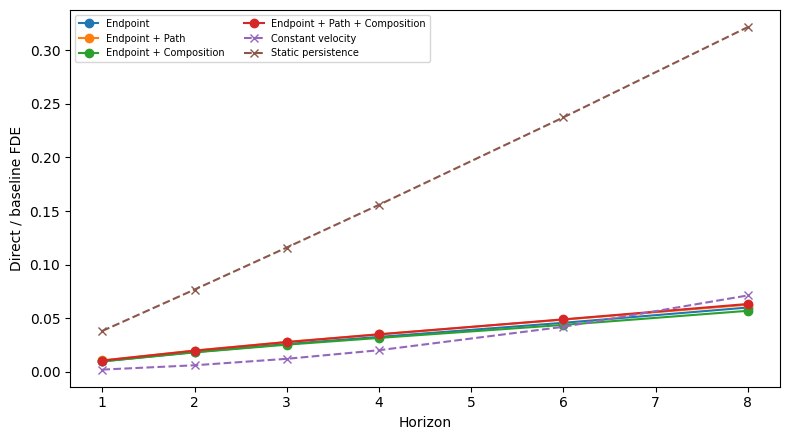

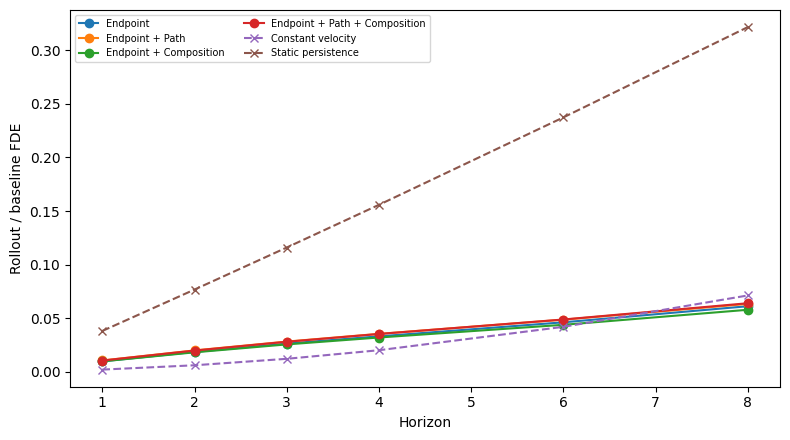

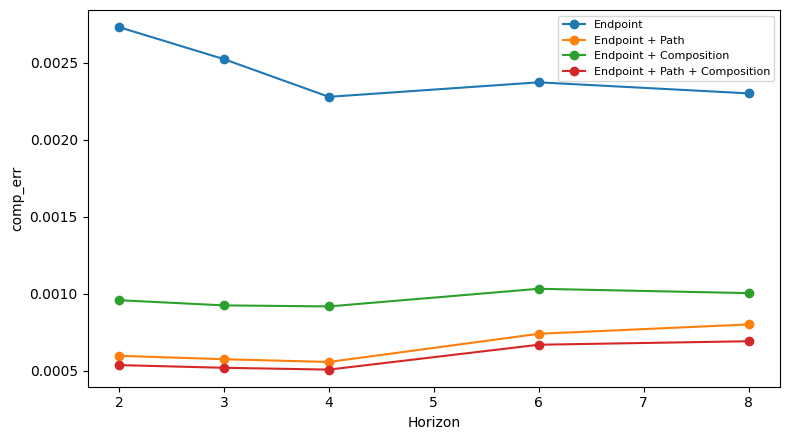

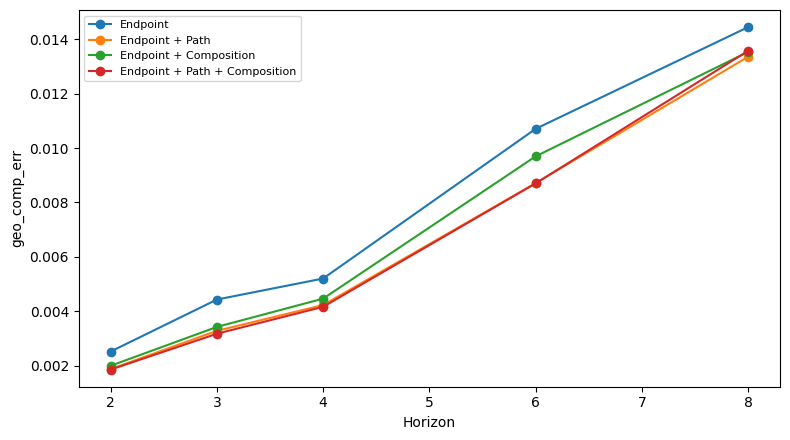


Partition generalization:


rollout_fde            \
                                                           mean       std   
variant                       category                                      
Endpoint                      heldout_seen_segments    0.050709  0.022721   
                              unseen_segments          0.046912  0.021722   
Endpoint + Composition        heldout_seen_segments    0.047770  0.021066   
                              unseen_segments          0.044675  0.020220   
Endpoint + Path               heldout_seen_segments    0.052273  0.022281   
                              unseen_segments          0.049162  0.021713   
Endpoint + Path + Composition heldout_seen_segments    0.052511  0.023589   
                              unseen_segments          0.049416  0.023011   

                                                     comp_err            \
                                                         mean       std   
variant                       category                                    
Endpoint                      heldout_seen_segments  0.011338  0.007176   
                              unseen_segments        0.002351  0.001114   
Endpoint + Composition        heldout_seen_segments  0.004539  0.002900   
                              unseen_segments        0.000963  0.000459   
Endpoint + Path               heldout_seen_segments  0.002857  0.001639   
                              unseen_segments        0.000641  0.000272   
Endpoint + Path + Composition heldout_seen_segments  0.002595  0.001500   
                              unseen_segments        0.000571  0.000237   

                                                    geo_comp_err            
                                                            mean       std  
variant                       category                                      
Endpoint                      heldout_seen_segments     0.014284  0.008010  
                              unseen_segments           0.009014  0.005588  
Endpoint + Composition        heldout_seen_segments     0.012040  0.007061  
                              unseen_segments           0.008030  0.005355  
Endpoint + Path               heldout_seen_segments     0.011050  0.006196  
                              unseen_segments           0.007776  0.005215  
Endpoint + Path + Composition heldout_seen_segments     0.010959  0.006141  
                              unseen_segments           0.007823  0.005379

In [13]:
# ---------- Diagnostic curves and tables ----------
# Mean curves across seeds and samples.
curve_stats = (
    primary_df
    .groupby(['variant', 'horizon'])[['direct_fde', 'rollout_fde', 'comp_err', 'geo_comp_err']]
    .mean()
    .reset_index()
)
baseline_curve = baseline_df.groupby(['baseline', 'horizon'])['fde'].mean().reset_index()

# Target-relative direct FDE with causal baselines.
plt.figure(figsize=(8, 4.5))
for variant in variants:
    d = curve_stats[curve_stats.variant == variant]
    plt.plot(d.horizon, d.direct_fde, marker='o', label=variant)
for name in baseline_curve.baseline.unique():
    d = baseline_curve[baseline_curve.baseline == name]
    plt.plot(d.horizon, d.fde, marker='x', linestyle='--', label=name)
plt.xlabel('Horizon')
plt.ylabel('Direct / baseline FDE')
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'direct_fde_vs_horizon_with_baselines.png', dpi=180)
plt.show()

# Recursive rollout FDE with causal baselines for reference.
plt.figure(figsize=(8, 4.5))
for variant in variants:
    d = curve_stats[curve_stats.variant == variant]
    plt.plot(d.horizon, d.rollout_fde, marker='o', label=variant)
for name in baseline_curve.baseline.unique():
    d = baseline_curve[baseline_curve.baseline == name]
    plt.plot(d.horizon, d.fde, marker='x', linestyle='--', label=name)
plt.xlabel('Horizon')
plt.ylabel('Rollout / baseline FDE')
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'rollout_fde_vs_horizon_with_baselines.png', dpi=180)
plt.show()

# Composition plots exclude the trivial J=1 path automatically (NaN at H=1).
for metric in ['comp_err', 'geo_comp_err']:
    plt.figure(figsize=(8, 4.5))
    for variant in variants:
        d = curve_stats[curve_stats.variant == variant].dropna(subset=[metric])
        plt.plot(d.horizon, d[metric], marker='o', label=variant)
    plt.xlabel('Horizon')
    plt.ylabel(metric)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f'{metric}_vs_horizon_nontrivial.png', dpi=180)
    plt.show()

# Partition-generalization summary.
part_stats = (
    partition_df
    .groupby(['variant', 'category'])[['rollout_fde', 'comp_err', 'geo_comp_err']]
    .agg(['mean', 'std'])
)
part_stats.to_csv(RESULT_DIR / 'partition_generalization_summary.csv')
print('\nPartition generalization:')
display(part_stats)


In [14]:
# ---------- Sanity, leakage, and interpretation checks ----------
assert set(train_seeds).isdisjoint(val_seeds)
assert set(train_seeds).isdisjoint(test_seeds)
assert set(val_seeds).isdisjoint(test_seeds)
assert set(CFG.unseen_horizons).isdisjoint(CFG.train_horizons)
assert max(CFG.train_horizons) <= CFG.seq_len - CFG.context_len

seen_lengths = set(CFG.train_horizons)
for H, plist in HELDOUT_SEEN_SEGMENT_PARTITIONS.items():
    for p in plist:
        assert sum(p) == H
        assert all(x in seen_lengths for x in p)
        assert p not in TRAIN_PARTITIONS[H]
for H, plist in UNSEEN_SEGMENT_PARTITIONS.items():
    for p in plist:
        assert sum(p) == H
        assert any(x not in seen_lengths for x in p)
for H in CFG.unseen_horizons:
    assert sum(PRIMARY_PARTITIONS[H]) == H
    assert all(x in seen_lengths for x in PRIMARY_PARTITIONS[H])

# H=1 must not contribute to composition aggregates.
assert primary_df.loc[primary_df.horizon == 1, 'comp_err'].isna().all()
assert primary_df.loc[primary_df.horizon == 1, 'geo_comp_err'].isna().all()


# Causal feature-construction smoke check: changing future states after t must not
# change the student encoder input/features for history ending at t.
_check = test_ds[0]
_t0 = int(_check['t'])
_hist_mu = _check['mu'][_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_hist_cov = _check['cov'][_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_gid = _check['group_ids'].unsqueeze(0).to(DEVICE)
_g1, _m1 = causal_gaussian_features(_hist_mu, _hist_cov, _gid, CFG)
# A future-only perturbation cannot enter the already-sliced causal history.
_future_perturbed = _check['mu'].clone()
_future_perturbed[_t0+1:] += 999.0
_hist_mu2 = _future_perturbed[_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_g2, _m2 = causal_gaussian_features(_hist_mu2, _hist_cov, _gid, CFG)
assert torch.equal(_g1, _g2) and torch.equal(_m1, _m2)

# Verify the finite differences are exactly causal and numerically correct.
_raw_v = (_hist_mu[:, -1] - _hist_mu[:, -2]) / CFG.velocity_scale
_raw_prev_v = (_hist_mu[:, -2] - _hist_mu[:, -3]) / CFG.velocity_scale
_expected_a = (_raw_v - _raw_prev_v) * (CFG.velocity_scale / CFG.acceleration_scale)
_, _motion = causal_gaussian_features(_hist_mu, _hist_cov, _gid, CFG)
# motion layout: rel-history | velocity | acceleration | delta-cov
_rel_dim = 3 * (CFG.context_len - 1)
assert torch.allclose(_motion[..., _rel_dim:_rel_dim+3], _raw_v, atol=1e-6)
assert torch.allclose(_motion[..., _rel_dim+3:_rel_dim+6], _expected_a, atol=1e-6)

print('Leakage/design checks passed:')
print('  ✓ train/validation/test scene seeds are disjoint')
print('  ✓ unseen horizons are excluded from training')
print('  ✓ checkpoint selection uses validation target accuracy only')
print('  ✓ Experiment 1 trains composed paths against targets only through L_path, when enabled')
print('  ✓ H=1 is excluded from composition metrics')
print('  ✓ held-out seen-segment partitions contain only trained segment lengths and were not trained')
print('  ✓ unseen-segment partitions are reported separately')
print('  ✓ motion-aware encoder features use only the causal context history')
print('  ✓ explicit velocity/acceleration finite differences passed numerical checks')
print('  ✓ constant velocity uses only the last two causal context states')

# Useful automatic diagnostic: compare learned target accuracy with trivial baselines.
learned_means = summary_df.groupby('variant')[['direct_fde', 'rollout_fde']].mean()
static_seen = float(baseline_summary.loc[baseline_summary.baseline == 'Static persistence', 'seen_fde'].iloc[0])
cv_seen = float(baseline_summary.loc[baseline_summary.baseline == 'Constant velocity', 'seen_fde'].iloc[0])
print(f'\nSeen-horizon baseline FDE: static={static_seen:.5f}, constant-velocity={cv_seen:.5f}')
display(learned_means)

best_learned = learned_means.direct_fde.min()
if best_learned >= static_seen:
    print('WARNING: no learned variant beats static persistence in mean seen-horizon direct FDE.')
else:
    print('At least one learned variant beats static persistence in mean seen-horizon direct FDE.')
if best_learned >= cv_seen:
    print('NOTE: constant velocity remains stronger than the learned variants on mean seen-horizon direct FDE.')
else:
    print('At least one learned variant beats constant velocity in mean seen-horizon direct FDE.')


Leakage/design checks passed:
  ✓ train/validation/test scene seeds are disjoint
  ✓ unseen horizons are excluded from training
  ✓ checkpoint selection uses validation target accuracy only
  ✓ Experiment 1 trains composed paths against targets only through L_path, when enabled
  ✓ H=1 is excluded from composition metrics
  ✓ held-out seen-segment partitions contain only trained segment lengths and were not trained
  ✓ unseen-segment partitions are reported separately
  ✓ motion-aware encoder features use only the causal context history
  ✓ explicit velocity/acceleration finite differences passed numerical checks
  ✓ constant velocity uses only the last two causal context states

Seen-horizon baseline FDE: static=0.14802, constant-velocity=0.02484


,direct_fde,rollout_fde
variant,,
Endpoint,0.030129,0.030608
Endpoint + Composition,0.029048,0.029399
Endpoint + Path,0.031949,0.032281
Endpoint + Path + Composition,0.032062,0.032357


At least one learned variant beats static persistence in mean seen-horizon direct FDE.
NOTE: constant velocity remains stronger than the learned variants on mean seen-horizon direct FDE.


## Result files produced

The result directory contains:

- `config.json` (including the motion-feature scales and center Huber threshold)
- one training/validation history CSV per variant and seed
- one best-validation checkpoint per variant and seed
- `summary_by_seed.csv` and `summary_mean_std.csv`
- `per_sample_metrics.csv`
- `partition_generalization_metrics.csv` and its summary
- static / constant-velocity baseline CSVs
- horizon diagnostic plots

The final cell packages the entire directory into one ZIP and triggers a browser download in Google Colab.


In [15]:
# ---------- Download all results as a ZIP ----------
zip_base = BASE_DIR / '4dgs_jepa_exp1_results_v3'
zip_path = shutil.make_archive(str(zip_base), 'zip', root_dir=RESULT_DIR)
print('Created:', zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as exc:
    print('Automatic browser download is available in Google Colab.')
    print('Local ZIP path:', zip_path)
    print('Download helper message:', exc)


Created: /content/4dgs_jepa_exp1_results_v3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>